# Full training and symbolic extraction

Follow the complete three-site training run from Hamiltonian labels to a checkpoint and extracted expressions. The saved run contains **100,000 samples and 1000 epochs**, not a smoke-test model. Set `RETRAIN = True` below to repeat the full optimization in this notebook; by default, inspect the completed and verified rerun. The original run's unrecorded CUDA initialization prevents an exact coefficient match.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from experiments.paper import ROOT
print('Repository:', ROOT)

Repository: /home/al/Documents/MNRKAN/NMRKan


In [2]:
from datetime import datetime, timezone
from experiments.paper import run
from experiments.reproduction import paper_run_root, load_run
RETRAIN = False
config=json.loads((ROOT/'configs/paper/three_site.json').read_text())
if RETRAIN:
    out=ROOT/'outputs/notebooks'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%f')
    result=run(config,out,train=True)
else:
    out=paper_run_root()/'three_site'
verified=load_run(out)
print('Artifacts:',out)
print('Samples:',verified['config']['samples'],'epochs:',verified['config']['epochs'])
print('Complete-sample RMSE:',verified['all_samples_neural']['rmse'])
print('Validation RMSE:',verified['validation_neural']['rmse'])

Artifacts: /home/al/Documents/MNRKAN/NMRKan/results/reproduced/2026-11-08/paper/three_site
Samples: 100000 epochs: 1000
Complete-sample RMSE: 0.017759573624732343
Validation RMSE: 0.017835496166569997


Extraction discrepancy: 6.994405055138486e-15
epsilon_1 = 0.0937403386884205*x_0**2 + 0.0227847106444288*x_0*x_1 + 0.0214394187587353*x_0 + 0.0934574569847356*x_1**2 + 0.0218971721872667*x_1 + 0.742846601455242
epsilon_2 = 0.103391995548538*x_0**2 - 0.37195074853318*x_0*x_1 + 0.360959025202588*x_0 + 0.103391260178043*x_1**2 + 0.360371776851851*x_1 - 1.23339231349838
epsilon_3 = -0.131843205485798*x_0**2 + 0.286913215554812*x_0*x_1 - 0.0269705568684302*x_0 - 0.131695372479983*x_1**2 - 0.0264086086124824*x_1 - 1.23755818214022
epsilon_4 = -0.0616880434162033*x_0**2 + 0.0542849841933228*x_0*x_1 - 0.354431761000947*x_0 - 0.0615561942704866*x_1**2 - 0.354578493090385*x_1 - 1.2722019727436


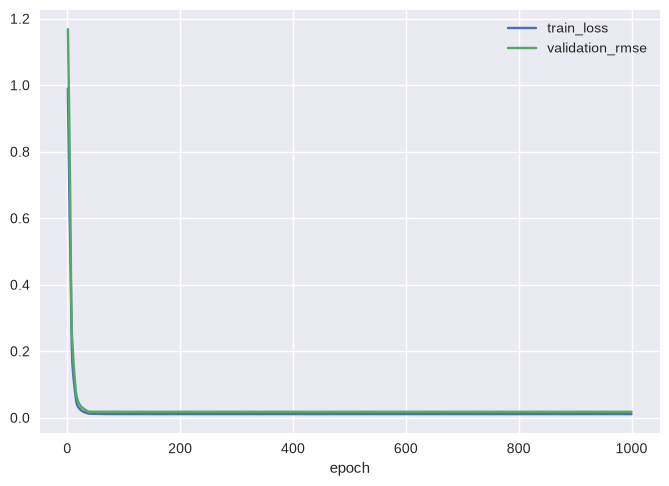

In [3]:
formulas=json.loads((out/'learned_formulas.json').read_text())
print('Extraction discrepancy:',formulas['extraction_max_abs_difference'])
for i,expression in enumerate(formulas['raw'],1):
    print(f'epsilon_{i} = {expression}')
pd.read_csv(out/'history.csv').plot(x='epoch',y=['train_loss','validation_rmse'])
plt.show()

The activation-selection vectors in this completed run all have support size one. Formula equivalence verifies algebraic extraction independently of predictive accuracy. The full-precision neural result and the processed symbolic result have separate metrics.

To repeat all four complete protocols with their published sample counts and epoch budgets:
```bash
python -m experiments.reproduction --train --root outputs/full_paper_repeat --summary outputs/full_paper_repeat/comparison.json
python -m experiments.check_notebooks --paper-runs outputs/full_paper_repeat
```
This uses fixed, recorded initialization seeds and does not search for a seed that happens to match a quoted paper metric.